&nbsp;

## HS-related PRO-seq data + `fanta.bio`

### Background

- 熱ストレスに関連する PRO-seq のデータをうまく活用できないかと考えていた
- [Danko-Lab/proseq2.0](https://github.com/Danko-Lab/proseq2.0) で再解析し、[bigWigAverageOverBed](https://open.bioqueue.org/home/knowledge/showKnowledge/sig/ucsc-bigwigaverageoverbed) で fanta.bio のシスエレメントごとに活性を統合するアプローチを考えている

In [1]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display


os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
metadata_proseq = pl.read_csv(
    "../../Data/metadata/metadata_2610/proseq_metadata_all_261001.tsv",
    separator="\t"
)

display(metadata_proseq)

sample_heat_id,sample_control_id,sample_name,protocol,organism,read_type,data_source,srr,srx,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_channel_count,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_molecule_ch1,sample_description,sample_platform_id,sample_contact_name,sample_contact_email,sample_contact_phone,sample_contact_institute,sample_contact_address,sample_contact_city,sample_contact_state,sample_contact_zip_postal_code,sample_contact_country,sample_instrument_model,sample_library_selection,sample_library_source,sample_library_strategy,gsm_id,sample_supplementary_file_1,…,center_name,tissue,chip_antibody,tissue_type,sample_characteristics_ch1,preconditioning,sequenced_molecule,sample_supplementary_file_2,sra_aspera,fastq_galaxy,sra_galaxy,fastq_md5,sra_md5,fastq_ftp,sra_ftp,fastq_aspera,hsf1_depletion,reanalyzed_by,sample_treatment_protocol_ch1,sample_growth_protocol_ch1,sample_extract_protocol_ch1,treatment1,processed_data_file,stress treatment temperature,stress treatment time,control treatment temperature,fastq_file_role,tag,scientific_name,tax_id,sra_file_role,tax_lineage,sample_data_processing,condition,antibody,country,collection_date
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str
"""SRR23989395""","""SRR23989399""","""dmso_20_r1_pro-seq_ vs dmso_0_…","""null""","""null""","""null""","""null""","""null""","""null""","""DMSO_20_R1 [PRO-seq] vs DMSO_0…","""GSM7119235 vs GSM7119231""","""Public on Dec 19 2024""","""Mar 28 2023""","""Dec 19 2024""","""SRA""",1,"""wild type OV90 cells""","""Homo sapiens""",9606,"""total RNA""","""PRO-seq from OV90 cells, prose…","""GPL24676""","""Taylor,K,Jones""","""tajo5912@colorado.edu""","""3606246612""","""University of Colorado Boulder""","""3415 Colorado Ave""","""Boulder""","""CO""",80301,"""USA""","""Illumina NovaSeq 6000""","""other""","""transcriptomic""","""OTHER""","""GSM7119235 vs GSM7119231""","""NONE""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""SRR23989394""","""SRR23989398""","""dmso_20_r2_pro-seq_ vs dmso_0_…","""null""","""null""","""null""","""null""","""null""","""null""","""DMSO_20_R2 [PRO-seq] vs DMSO_0…","""GSM7119236 vs GSM7119232""","""Public on Dec 19 2024""","""Mar 28 2023""","""Dec 19 2024""","""SRA""",1,"""wild type OV90 cells""","""Homo sapiens""",9606,"""total RNA""","""PRO-seq from OV90 cells, prose…","""GPL24676""","""Taylor,K,Jones""","""tajo5912@colorado.edu""","""3606246612""","""University of Colorado Boulder""","""3415 Colorado Ave""","""Boulder""","""CO""",80301,"""USA""","""Illumina NovaSeq 6000""","""other""","""transcriptomic""","""OTHER""","""GSM7119236 vs GSM7119232""","""NONE""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""SRR23989382""","""SRR23989399""","""dmso_45_r1_pro-seq_ vs dmso_0_…","""null""","""null""","""null""","""null""","""null""","""null""","""DMSO_45_R1 [PRO-seq] vs DMSO_0…","""GSM7119239 vs GSM7119231""","""Public on Dec 19 2024""","""Mar 28 2023""","""Dec 19 2024""","""SRA""",1,"""wild type OV90 cells""","""Homo sapiens""",9606,"""total RNA""","""PRO-seq from OV90 cells, prose…","""GPL24676""","""Taylor,K,Jones""","""tajo5912@colorado.edu""","""3606246612""","""University of Colorado Boulder""","""3415 Colorado Ave""","""Boulder""","""CO""",80301,"""USA""","""Illumina NovaSeq 6000""","""other""","""transcriptomic""","""OTHER""","""GSM7119239 vs GSM7119231""","""NONE""",…,null,null,null,null,null,null,

&nbsp;

&nbsp;

&nbsp;

## Step 1: Concatenate `bigWigAverageOverBed` result TSV files

- `bigWigAverageOverBed` で出力された結果から、`name`, `size`, `mean0`カラムを抜き出し、concat するプロセス

In [3]:
# Build wide matrices (cre_id, size, mean0 per SRR) for plus / minus separately
DATA_DIR = pathlib.Path("../../out/proseq_test/")

AVERAGE_SCHEMA = {
    "name": pl.Utf8,
    "size": pl.UInt32,
    "covered": pl.UInt32,
    "sum": pl.Float64,
    "mean0": pl.Float64,
    "mean": pl.Float64,
    "min": pl.Float64,
    "max": pl.Float64,
}


def load_mean0_frame(path: pathlib.Path) -> pl.DataFrame:
    """Read one bigWigAverageOverBed TSV and keep cre_id / size / mean0."""
    srr = path.name.split("_")[0]
    return (
        pl.read_csv(
            path,
            separator="\t",
            schema_overrides=AVERAGE_SCHEMA,
            columns=["name", "size", "mean0"],
            n_threads=16,
        )
        .rename({"name": "cre_id", "mean0": srr})
        .sort("cre_id")
    )


def build_strand_matrix(strand: str) -> pl.DataFrame:
    """Horizontally concat sample mean0 columns for a given strand."""
    paths = sorted(DATA_DIR.glob(f"*_{strand}.rpm_fantabio_v1.2.1_average.tsv"))
    if not paths:
        raise FileNotFoundError(f"No *_{strand}.rpm_fantabio_v1.2.1_average.tsv in {DATA_DIR}")

    frames = [load_mean0_frame(p) for p in paths]

    # Same BED -> same cre_id set; sort then horizontal concat (keep cre_id/size once)
    n_rows = frames[0].height
    for path, frame in zip(paths, frames):
        if frame.height != n_rows:
            raise ValueError(f"Row count mismatch: {path.name} has {frame.height}, expected {n_rows}")

    parts = [frames[0]] + [frame.drop(["cre_id", "size"]) for frame in frames[1:]]
    return pl.concat(parts, how="horizontal")


proseq_plus = build_strand_matrix("plus")
proseq_minus = build_strand_matrix("minus")

print(f"plus files:  {[c for c in proseq_plus.columns if c not in ('cre_id', 'size')]}")
print(f"minus files: {[c for c in proseq_minus.columns if c not in ('cre_id', 'size')]}")
display(proseq_plus)
display(proseq_minus)

plus files:  ['SRR11024623', 'SRR11024624', 'SRR11024625', 'SRR11024626', 'SRR11024627', 'SRR11024628', 'SRR12267707', 'SRR12267708', 'SRR12267709', 'SRR12267710', 'SRR12267711', 'SRR12267712', 'SRR12267713', 'SRR12267714', 'SRR14352131', 'SRR14352132', 'SRR14352133', 'SRR14352134', 'SRR14352135', 'SRR14352136', 'SRR14352137', 'SRR14352138', 'SRR19077081', 'SRR19077082', 'SRR19077083', 'SRR19077084', 'SRR19077085', 'SRR19077086', 'SRR19077087', 'SRR19077088', 'SRR19077089', 'SRR19077090', 'SRR19077091', 'SRR19077092', 'SRR19077093', 'SRR19077094', 'SRR19077095', 'SRR19077096', 'SRR20631358', 'SRR20631359', 'SRR20631361', 'SRR20631362', 'SRR20631364', 'SRR20631365', 'SRR21140707', 'SRR21140708', 'SRR21140709', 'SRR21140710', 'SRR21140711', 'SRR21140712', 'SRR21140713', 'SRR21140714', 'SRR21140715', 'SRR21140716', 'SRR21140717', 'SRR21140718', 'SRR21140719', 'SRR21140720', 'SRR21140721', 'SRR21140722', 'SRR21140723', 'SRR21140724', 'SRR21140725', 'SRR21140726', 'SRR21140727', 'SRR2114072

cre_id,size,SRR11024623,SRR11024624,SRR11024625,SRR11024626,SRR11024627,SRR11024628,SRR12267707,SRR12267708,SRR12267709,SRR12267710,SRR12267711,SRR12267712,SRR12267713,SRR12267714,SRR14352131,SRR14352132,SRR14352133,SRR14352134,SRR14352135,SRR14352136,SRR14352137,SRR14352138,SRR19077081,SRR19077082,SRR19077083,SRR19077084,SRR19077085,SRR19077086,SRR19077087,SRR19077088,SRR19077089,SRR19077090,SRR19077091,SRR19077092,SRR19077093,…,SRR23989382,SRR23989392,SRR23989393,SRR23989394,SRR23989395,SRR23989396,SRR23989397,SRR23989398,SRR23989399,SRR4454567,SRR4454568,SRR4454569,SRR4454570,SRR6904125,SRR6904126,SRR6904127,SRR6904128,SRR6904129,SRR6904130,SRR6904131,SRR6904132,SRR8669162,SRR8669163,SRR8669164,SRR8669165,SRR8669166,SRR8669167,SRR8669168,SRR8669169,SRR8669170,SRR8669171,SRR8669172,SRR8669173,SRR8669174,SRR8669175,SRR8669176,SRR8669177
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_1""",78,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100""",476,0.000248,0.000668,0.001667,0.001803,0.001257,0.00334,0.000702,0.000282,0.001075,0.001542,0.001072,0.000431,0.000135,0.00065,0.000055,0.000053,0.000127,0.000079,0.000497,0.000513,0.00042,0.000419,0.000381,0.000255,0.001723,0.000425,0.001509,0.000988,0.002182,0.0010972,0.0039074,0.000519,0.0032666,0.00064,0.0045839,…,0.000596,0.001207,0.000398,0.002232,0.0018089,0.002576,0.000238,0.003462,0.001157,0.0033638,0.002697,0.00051,0.000205,0.002039,0.001752,0.001839,0.002246,0.005547,0.003287,0.007038,0.003002,0.000885,0.00146,0.000411,0.000786,0.000377,0.000754,0.001434,0.00058,0.000913,0.000393,0.000804,0.000363,0.000586,0.000577,0.000697,0.000365
"""FCHS_1000""",658,0.007993,0.008129,0.0108362,0.0111073,0.008447,0.007438,0.002284,0.0165011,0.00175,0.009086,0.000665,0.008567,0.000686,0.005881,0.0135481,0.0128641,0.0130273,0.0144106,0.0113483,0.0111378,0.0113319,0.0122418,0.011846,0.006025,0.0244636,0.00684,0.0148029,0.0066496,0.0350697,0.007937,0.0293109,0.0111446,0.0295384,0.006548,0.0292042,…,0.006509,0.00991,0.003419,0.008214,0.00493,0.006336,0.003889,0.0056838,0.006172,0.006643,0.004878,0.000718,0.00111,0.005244,0.001991,0.002297,0.009958,0.0035975,0.002526,0.003687,0.004247,0.004269,0.004487,0.0021792,0.001989,0.001254,0.004226,0.002904,0.001783,0.00099,0.001933,0.003799,0.001487,0.001602,0.003249,0.002153,0.001744
"""FCHS_100000""",359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100001""",248,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_99995""",615,0.0,0.0,0.0,0.000042,0.0,0.0,0.000091,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000021,0.00002,0.000123,0.0,0.000244,0.0,0.000088,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.000037,0.0,0.0,0.000075,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000079,0.0,0.0,0.000129,0.0,0.000148,0.0,0.0,0.000052,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_99996""",205,0.0,0.0,0.0,0.0,0.0,0.

cre_id,size,SRR11024623,SRR11024624,SRR11024625,SRR11024626,SRR11024627,SRR11024628,SRR12267707,SRR12267708,SRR12267709,SRR12267710,SRR12267711,SRR12267712,SRR12267713,SRR12267714,SRR14352131,SRR14352132,SRR14352133,SRR14352134,SRR14352135,SRR14352136,SRR14352137,SRR14352138,SRR19077081,SRR19077082,SRR19077083,SRR19077084,SRR19077085,SRR19077086,SRR19077087,SRR19077088,SRR19077089,SRR19077090,SRR19077091,SRR19077092,SRR19077093,…,SRR23989382,SRR23989392,SRR23989393,SRR23989394,SRR23989395,SRR23989396,SRR23989397,SRR23989398,SRR23989399,SRR4454567,SRR4454568,SRR4454569,SRR4454570,SRR6904125,SRR6904126,SRR6904127,SRR6904128,SRR6904129,SRR6904130,SRR6904131,SRR6904132,SRR8669162,SRR8669163,SRR8669164,SRR8669165,SRR8669166,SRR8669167,SRR8669168,SRR8669169,SRR8669170,SRR8669171,SRR8669172,SRR8669173,SRR8669174,SRR8669175,SRR8669176,SRR8669177
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_1""",78,0.0,0.0,0.0,0.0,0.0,0.0,-0.000714,0.0,0.0,0.0,-0.000935,0.0,-0.000827,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.00046,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100""",476,-0.000124,-0.000472,-0.000572,-0.000656,-0.001617,-0.000786,-0.002456,-0.001408,-0.001479,-0.001763,-0.000766,-0.001184,-0.000406,-0.001951,-0.000055,-0.000027,-0.000051,0.0,-0.000248,-0.000118,-0.000382,-0.000229,0.0,0.0,-0.000215,-0.000319,-0.000116,-0.000247,0.0,-0.000329,0.0,-0.000173,0.0,0.0,-0.000241,…,-0.000145,-0.000325,0.0,0.0,-0.000042,-0.000206,0.0,-0.000272,0.0,-0.000673,-0.000385,-0.000369,-0.000102,-0.00068,-0.000751,-0.00117,-0.000507,-0.000574,-0.001438,-0.003762,-0.001668,-0.00177,-0.003649,-0.000411,-0.001179,-0.000452,-0.001508,-0.004014,-0.00029,-0.001825,-0.000236,-0.000857,-0.000786,-0.000586,-0.000834,-0.000507,-0.001096
"""FCHS_1000""",658,-0.000149,-0.001165,-0.001548,-0.000356,-0.001689,-0.002179,-0.001607,-0.000407,-0.000875,-0.000797,-0.000775,-0.000701,-0.000392,-0.001411,0.0,-0.000116,-0.000092,-0.000153,0.0,-0.000057,0.0,-0.000414,-0.001377,-0.000861,-0.000857,-0.000231,-0.000777,-0.000751,-0.000526,-0.000516,-0.001413,-0.000563,-0.00209,0.0,-0.001891,…,-0.000396,-0.001982,-0.000851,-0.000351,-0.001339,-0.000075,-0.000138,0.0,-0.000035,-0.000195,-0.000209,-0.000554,-0.00037,-0.000164,0.0,0.0,0.0,-0.001384,-0.000892,-0.000878,-0.000386,-0.000213,-0.000528,-0.001189,0.0,-0.000818,-0.000273,-0.000207,-0.000734,-0.00066,-0.000512,-0.000426,-0.001181,-0.000895,-0.000186,-0.001099,-0.00148
"""FCHS_100000""",359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.000222,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100001""",248,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_99995""",615,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.000083,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.000188,-0.000258,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_99996""",205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.

&nbsp;

&nbsp;

&nbsp;

## Step 2: Calculate log2 fold change (`mean0`)

- メタデータの `sample_heat_id` / `sample_control_id` ペアを使い、`log2((HS + 1) / (control + 1))` を算出
- `plus` / `minus` それぞれで実行
- 行列に存在しない SRR ペアはスキップし、`failed_pairs` に記録


In [4]:
# Calculate log2((HS + 1) / (control + 1)) for each metadata pair (plus / minus separately)
# Based on notebooks/HNscore/14_1_HNratio_polars_transcript_gencode.ipynb


def compute_hn_log2fc(
    mean0_table: pl.DataFrame,
    hn_pair: pl.DataFrame,
    id_cols: list[str] | None = None,
) -> tuple[pl.DataFrame, list[dict]]:
    if id_cols is None:
        id_cols = ["cre_id", "size"]

    HNlog2fc = mean0_table.select(id_cols)
    failed_pairs: list[dict] = []

    for row in hn_pair.to_dicts():
        h = row["sample_heat_id"]  # H (heat-stress)
        n = row["sample_control_id"]  # N (non-treatment)

        h_exists = h in mean0_table.columns
        n_exists = n in mean0_table.columns

        print(f"Stress column exists: {h_exists}, Control column exists: {n_exists}\n")

        if h_exists and n_exists:
            h_count = mean0_table[h].count()
            n_count = mean0_table[n].count()
            rows_match = h_count == n_count

            h_nulls = mean0_table[h].null_count()
            n_nulls = mean0_table[n].null_count()

            print(f"Null values in Stress column: {h_nulls}, in Control column: {n_nulls}\n")

            if rows_match and h_nulls == 0 and n_nulls == 0:
                # log2 fold change with pseudocount +1
                log2fc_column = (
                    ((mean0_table[h] + 0.01) / (mean0_table[n] + 0.01))
                    .log(base=2)
                    .alias(h)
                )
                HNlog2fc = HNlog2fc.with_columns(log2fc_column)
                print(f"Successfully processed combination: {h} and {n}")
            else:
                print(f"Data integrity check failed. This combination {h} and {n} is skipped.")
                failed_pairs.append({
                    "sample_heat_id": h,
                    "sample_control_id": n,
                    "failure_reason": (
                        f"Data integrity check failed: rows_match={rows_match}, "
                        f"h_nulls={h_nulls}, n_nulls={n_nulls}"
                    ),
                })
        else:
            print("Error: One or both columns do not exist. This combination is skipped.\n")
            failed_pairs.append({
                "sample_heat_id": h,
                "sample_control_id": n,
                "failure_reason": f"Column missing: h_exists={h_exists}, n_exists={n_exists}",
            })

    return HNlog2fc, failed_pairs


print("=== plus strand ===")
proseq_log2fc_plus, failed_pairs_plus = compute_hn_log2fc(proseq_plus, metadata_proseq)

print("\n=== minus strand ===")
proseq_log2fc_minus, failed_pairs_minus = compute_hn_log2fc(proseq_minus, metadata_proseq)

display(proseq_log2fc_plus)
display(proseq_log2fc_minus)

failed_rows = [
    {**row, "strand": strand}
    for strand, pairs in [("plus", failed_pairs_plus), ("minus", failed_pairs_minus)]
    for row in pairs
]
if failed_rows:
    failed_pairs_df = pl.DataFrame(failed_rows)
    print(f"\nTotal failed pairs: {failed_pairs_df.height}")
    display(failed_pairs_df)
else:
    print("\nAll pairs were successfully processed!")

=== plus strand ===
Stress column exists: True, Control column exists: True

Null values in Stress column: 0, in Control column: 0

Successfully processed combination: SRR23989395 and SRR23989399
Stress column exists: True, Control column exists: True

Null values in Stress column: 0, in Control column: 0

Successfully processed combination: SRR23989394 and SRR23989398
Stress column exists: True, Control column exists: True

Null values in Stress column: 0, in Control column: 0

Successfully processed combination: SRR23989382 and SRR23989399
Stress column exists: True, Control column exists: True

Null values in Stress column: 0, in Control column: 0

Successfully processed combination: SRR23989378 and SRR23989398
Stress column exists: True, Control column exists: True

Null values in Stress column: 0, in Control column: 0

Successfully processed combination: SRR23989393 and SRR23989397
Stress column exists: True, Control column exists: True

Null values in Stress column: 0, in Control

cre_id,size,SRR23989395,SRR23989394,SRR23989382,SRR23989378,SRR23989393,SRR23989392,SRR23989377,SRR23989376,SRR14352132,SRR14352134,SRR14352136,SRR14352138,SRR21140707,SRR21140708,SRR21140709,SRR21140710,SRR21140715,SRR21140716,SRR21140717,SRR21140718,SRR21140723,SRR21140724,SRR21140725,SRR21140726,SRR12267709,SRR12267710,SRR12267711,SRR12267712,SRR12267713,SRR12267714,SRR19077094,SRR19077093,SRR19077090,SRR19077089,SRR19077086,SRR19077085,SRR19077082,SRR19077081,SRR8669164,SRR8669165,SRR8669166,SRR8669169,SRR8669170,SRR8669171,SRR8669173,SRR8669174,SRR8669176,SRR8669177,SRR4454569,SRR4454570,SRR6904129,SRR6904130,SRR6904131,SRR6904132,SRR11024624,SRR11024625,SRR11024627,SRR11024628,SRR20631364,SRR20631361,SRR20631358
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_1""",78,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.129562,0.0,0.0
"""FCHS_100""",476,0.081937,-0.138204,-0.074484,-0.257696,0.022436,-0.16622,-0.003346,-0.149455,-0.000311,-0.006843,0.002268,-0.000142,-0.018204,0.01362,0.017691,0.065888,-0.037178,-0.050295,-0.010776,-0.044756,0.040133,0.066209,0.064529,-0.052051,0.049524,0.166886,0.049068,0.020763,-0.078429,0.050839,0.054293,0.240306,-0.016458,0.068054,-0.014215,-0.081894,-0.023719,-0.175443,-0.064288,-0.087427,-0.069005,-0.023495,-0.06729,-0.049228,-0.060123,-0.029342,0.016158,-0.029222,-0.346515,-0.315265,0.368946,0.177087,0.525246,0.086475,0.057969,0.187135,-0.068296,0.176562,-0.065549,0.056894,0.003492
"""FCHS_1000""",658,-0.115311,0.215747,0.029691,0.067026,-0.049729,0.285442,0.100141,0.224477,-0.042527,0.084162,-0.014296,0.060261,-0.362514,-0.15865,-0.392427,-0.26582,0.194006,0.092339,0.178825,0.261787,-0.021665,-0.044101,-0.122834,-0.09124,-0.064095,-0.473534,-0.20397,-0.5133,-0.201099,-0.738744,-0.206994,0.119957,0.35366,-0.008325,-0.107465,-0.861649,-0.071566,-0.657704,-0.228468,-0.273033,-0.342465,-0.271772,-0.231581,-0.253529,-0.264522,-0.250159,-0.124554,-0.173912,-0.634903,-0.421235,-0.164863,0.062937,0.154425,-0.486276,0.010929,0.211689,-0.194385,-0.275546,-0.549991,0.393915,-0.001744
"""FCHS_100000""",359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100001""",248,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_99995""",615,0.0,0.010796,0.005382,0.02069,0.0,0.0,0.010831,0.014298,0.002969,0.014755,0.034842,0.012711,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.013,0.0,-0.013,0.0,-0.013,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.011381,0.021201,0.0,-0.018545,0.007431,0.0,0.0,-0.006089,-0.006089,0.0,0.014894,-0.0017
"""FCHS_99996""",205,0.0,0.0,0.06329,0.0,0.0,0.0,0.0,0.0,-0.009251,0.008823,0.0,0.025312,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.06722,0.0,0.0,0.0,0.0,0.0,0.0,-0.012837,0.0267,-0.010171
"""FCHS_99997""",706,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00517,0.0,-0.004021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.

cre_id,size,SRR23989395,SRR23989394,SRR23989382,SRR23989378,SRR23989393,SRR23989392,SRR23989377,SRR23989376,SRR14352132,SRR14352134,SRR14352136,SRR14352138,SRR21140707,SRR21140708,SRR21140709,SRR21140710,SRR21140715,SRR21140716,SRR21140717,SRR21140718,SRR21140723,SRR21140724,SRR21140725,SRR21140726,SRR12267709,SRR12267710,SRR12267711,SRR12267712,SRR12267713,SRR12267714,SRR19077094,SRR19077093,SRR19077090,SRR19077089,SRR19077086,SRR19077085,SRR19077082,SRR19077081,SRR8669164,SRR8669165,SRR8669166,SRR8669169,SRR8669170,SRR8669171,SRR8669173,SRR8669174,SRR8669176,SRR8669177,SRR4454569,SRR4454570,SRR6904129,SRR6904130,SRR6904131,SRR6904132,SRR11024624,SRR11024625,SRR11024627,SRR11024628,SRR20631364,SRR20631361,SRR20631358
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_1""",78,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.106823,0.0,-0.034721,0.0,-0.017651,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.067923,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-3.57703,0.317717,0.363373
"""FCHS_100""",476,-0.006082,0.039825,-0.021051,0.009213,0.0,-0.017634,-0.025507,-0.155968,0.00417,0.007358,0.019093,0.022826,0.098945,-0.007862,0.083359,-0.051534,-0.024594,0.0,0.0,0.015233,-0.035462,0.0,-0.055382,-0.018078,0.175729,-0.060837,0.291666,0.037091,0.346737,-0.094199,-0.052973,-0.004128,-0.025192,0.0,0.01219,-0.016848,0.04673,0.031415,0.220589,0.473987,0.214349,0.193287,0.449643,0.201321,0.011202,0.042157,0.050642,-0.041825,0.046293,0.041846,0.016275,-0.111366,-0.501243,-0.188184,-0.051693,-0.067035,-0.15657,-0.020233,0.037335,-0.075733,-0.095536
"""FCHS_1000""",658,-0.202355,-0.05155,-0.053233,-0.054582,-0.108382,-0.307879,-0.147911,-0.196856,-0.016767,-0.008894,-0.008264,-0.060935,0.0,0.0,0.0,0.0,-0.010987,0.02118,-0.010088,0.033265,0.020637,0.0,-0.009353,-0.008853,0.120677,-0.059816,0.136366,-0.044833,0.195131,-0.159504,-0.471089,0.144116,-0.083675,0.118498,-0.036174,-0.038714,-0.096194,-0.084552,-0.151439,0.078246,-0.091952,-0.070153,-0.068297,-0.035908,-0.118468,-0.072465,-0.140986,-0.204025,-0.053836,-0.023934,-0.191015,-0.134728,-0.132548,-0.056811,-0.157048,-0.220925,-0.214702,-0.302343,-0.126561,-0.056996,-0.069232
"""FCHS_100000""",359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.032334,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100001""",248,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_99995""",615,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.012072,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.027357,-0.037741,0.0,0.0,0.0,0.0,0.003124,-0.00192,0.001702
"""FCHS_99996""",205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_99997""",706,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.002847,0.0,0.0



Total failed pairs: 4


sample_heat_id,sample_control_id,failure_reason,strand
str,str,str,str
"""SRR1823903""","""SRR1823901""","""Column missing: h_exists=False…","""plus"""
"""SRR1823904""","""SRR1823902""","""Column missing: h_exists=False…","""plus"""
"""SRR1823903""","""SRR1823901""","""Column missing: h_exists=False…","""minus"""
"""SRR1823904""","""SRR1823902""","""Column missing: h_exists=False…","""minus"""


&nbsp;

&nbsp;

&nbsp;

## Step 3: Assign UP / DOWN / UNCHANGED flags

- log2FC が `threshold` 以上なら `UP`、`-threshold` 以下なら `DOWN`、それ以外は `UNCHANGED`
- `threshold = 1` は 2-fold（旧 HNscore の ratio threshold=2 に相当）
- `plus` / `minus` それぞれに適用


In [5]:
# Assign UP / DOWN / UNCHANGED flags from log2FC
# threshold=1 means 2-fold (equivalent to ratio threshold=2 in HNscore)
threshold = 1
id_cols = ["cre_id", "size"]


def categorize(x):
    if x >= threshold:
        return "UP"
    elif x <= -threshold:
        return "DOWN"
    else:
        return "UNCHANGED"


def assign_category_flags(log2fc_table: pl.DataFrame) -> pl.DataFrame:
    result = log2fc_table.with_columns([
        pl.col(col).map_elements(categorize, return_dtype=pl.String).alias(f"{col}_category")
        for col in log2fc_table.columns
        if col not in id_cols
    ])
    return result.drop(
        [col for col in result.columns if not col.endswith("_category") and col not in id_cols]
    )


proseq_category_plus = assign_category_flags(proseq_log2fc_plus)
proseq_category_minus = assign_category_flags(proseq_log2fc_minus)

display(proseq_category_plus)
display(proseq_category_minus)

# Quick count of flags per sample column
# for strand, df in [("plus", proseq_category_plus), ("minus", proseq_category_minus)]:
#     print(f"\n=== {strand} category counts ===")
#     for col in df.columns:
#         if col.endswith("_category"):
#             print(col, df[col].value_counts().sort("count", descending=True))

cre_id,size,SRR23989395_category,SRR23989394_category,SRR23989382_category,SRR23989378_category,SRR23989393_category,SRR23989392_category,SRR23989377_category,SRR23989376_category,SRR14352132_category,SRR14352134_category,SRR14352136_category,SRR14352138_category,SRR21140707_category,SRR21140708_category,SRR21140709_category,SRR21140710_category,SRR21140715_category,SRR21140716_category,SRR21140717_category,SRR21140718_category,SRR21140723_category,SRR21140724_category,SRR21140725_category,SRR21140726_category,SRR12267709_category,SRR12267710_category,SRR12267711_category,SRR12267712_category,SRR12267713_category,SRR12267714_category,SRR19077094_category,SRR19077093_category,SRR19077090_category,SRR19077089_category,SRR19077086_category,SRR19077085_category,SRR19077082_category,SRR19077081_category,SRR8669164_category,SRR8669165_category,SRR8669166_category,SRR8669169_category,SRR8669170_category,SRR8669171_category,SRR8669173_category,SRR8669174_category,SRR8669176_category,SRR8669177_category,SRR4454569_category,SRR4454570_category,SRR6904129_category,SRR6904130_category,SRR6904131_category,SRR6904132_category,SRR11024624_category,SRR11024625_category,SRR11024627_category,SRR11024628_category,SRR20631364_category,SRR20631361_category,SRR20631358_category
str,u32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""FCHS_1""",78,"""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED"""
"""FCHS_100""",476,"""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED"""
"""FCHS_1000""",658,"""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""",

cre_id,size,SRR23989395_category,SRR23989394_category,SRR23989382_category,SRR23989378_category,SRR23989393_category,SRR23989392_category,SRR23989377_category,SRR23989376_category,SRR14352132_category,SRR14352134_category,SRR14352136_category,SRR14352138_category,SRR21140707_category,SRR21140708_category,SRR21140709_category,SRR21140710_category,SRR21140715_category,SRR21140716_category,SRR21140717_category,SRR21140718_category,SRR21140723_category,SRR21140724_category,SRR21140725_category,SRR21140726_category,SRR12267709_category,SRR12267710_category,SRR12267711_category,SRR12267712_category,SRR12267713_category,SRR12267714_category,SRR19077094_category,SRR19077093_category,SRR19077090_category,SRR19077089_category,SRR19077086_category,SRR19077085_category,SRR19077082_category,SRR19077081_category,SRR8669164_category,SRR8669165_category,SRR8669166_category,SRR8669169_category,SRR8669170_category,SRR8669171_category,SRR8669173_category,SRR8669174_category,SRR8669176_category,SRR8669177_category,SRR4454569_category,SRR4454570_category,SRR6904129_category,SRR6904130_category,SRR6904131_category,SRR6904132_category,SRR11024624_category,SRR11024625_category,SRR11024627_category,SRR11024628_category,SRR20631364_category,SRR20631361_category,SRR20631358_category
str,u32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""FCHS_1""",78,"""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""DOWN""","""UNCHANGED""","""UNCHANGED"""
"""FCHS_100""",476,"""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED"""
"""FCHS_1000""",658,"""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UN

&nbsp;

&nbsp;

&nbsp;

## Step 4: Count UP / DOWN / UNCHANGED and compute HN score

- 各 CRE について、サンプル横断で `UP` / `DOWN` / `UNCHANGED` の出現数を集計
- `HN = UP - DOWN`、あわせて `log2((UP+1)/(DOWN+1))` も算出
- `plus` / `minus` それぞれで実行


In [6]:
# Count UP / DOWN / UNCHANGED across samples and compute HN score
# Same logic as notebooks/HNscore/15_1_HNscore_transcript_gencode.ipynb
# https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.sum_horizontal.html


def compute_hn_count(result: pl.DataFrame, threshold: int | float) -> pl.DataFrame:
    category_cols = [col for col in result.columns if col.endswith("_category")]
    id_cols = [col for col in result.columns if col not in category_cols]

    return (
        result.with_columns([
            pl.sum_horizontal([
                (pl.col(col) == "UP").cast(pl.Int32) for col in category_cols
            ]).alias(f"UP"),
            pl.sum_horizontal([
                (pl.col(col) == "DOWN").cast(pl.Int32) for col in category_cols
            ]).alias(f"DOWN"),
            pl.sum_horizontal([
                (pl.col(col) == "UNCHANGED").cast(pl.Int32) for col in category_cols
            ]).alias(f"UNCHANGED"),
        ])
        .drop(category_cols)
        .with_columns([
            (pl.col(f"UP") - pl.col(f"DOWN")).alias(f"HNscore"),
        ])
        .sort(by=f"HNscore", descending=True)
    )

In [7]:
proseq_hn_plus = compute_hn_count(proseq_category_plus, threshold)
proseq_hn_minus = compute_hn_count(proseq_category_minus, threshold)

display(proseq_hn_plus)
display(proseq_hn_minus)

cre_id,size,UP,DOWN,UNCHANGED,HNscore
str,u32,i32,i32,i32,i32
"""FCHS_354488""",479,61,0,0,61
"""FCHS_354489""",411,61,0,0,61
"""FCHS_564345""",227,61,0,0,61
"""FCHS_354487""",494,60,0,1,60
"""FCHS_383692""",419,60,0,1,60
…,…,…,…,…,…
"""FCHS_211253""",354,0,40,21,-40
"""FCHS_352293""",348,0,41,20,-41
"""FCHS_214390""",298,0,44,17,-44


cre_id,size,UP,DOWN,UNCHANGED,HNscore
str,u32,i32,i32,i32,i32
"""FCHS_513140""",349,53,0,8,53
"""FCHS_131437""",622,50,0,11,50
"""FCHS_72809""",280,50,0,11,50
"""FCHS_110365""",588,48,0,13,48
"""FCHS_83288""",654,47,0,14,47
…,…,…,…,…,…
"""FCHS_352237""",484,0,40,21,-40
"""FCHS_352238""",678,0,44,17,-44
"""FCHS_352239""",434,0,44,17,-44


In [13]:
#check
check_cre_plus = proseq_hn_plus.filter(
    pl.col("cre_id") == "FCHS_73490"
)

check_cre_minus = proseq_hn_minus.filter(
    pl.col("cre_id") == "FCHS_73490"
)

display(check_cre_plus)
display(check_cre_minus)

cre_id,size,UP,DOWN,UNCHANGED,HNscore
str,u32,i32,i32,i32,i32
"""FCHS_73490""",478,0,0,61,0


cre_id,size,UP,DOWN,UNCHANGED,HNscore
str,u32,i32,i32,i32,i32
"""FCHS_73490""",478,0,14,47,-14


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Calculate Directionality

fanta.bio の CRE directionality と同型の指標を、PRO-seq の `bigWigAverageOverBed` 出力から算出する。

$$
\mathrm{Directionality} = \frac{F - R}{F + R}
$$

- $F$ = ForwardCounts ≈ plus strand の `sum`（絶対値）
- $R$ = ReverseCounts ≈ minus strand の `sum`（絶対値）
- 範囲は概ね $[-1, 1]$（+1: plus 優位、$-1$: minus 優位、0: 両鎖同程度）

### Why `sum` (not `mean`)

| Column | Meaning | Use for directionality? |
|--------|---------|-------------------------|
| `sum` | Sum of signal over covered bases | **Yes** — closest to Counts |
| `mean0` | `sum / size` | OK numerically (same size → same ratio), but keep activity and directionality separate |
| `mean` | `sum / covered` | **No** — `covered` often differs between plus and minus |

### Caveats

- Minus-strand bigWig values are typically **negative** in these files → use `abs(sum)` for both strands.
- If $F + R = 0$, directionality is **null** (no signal; do not confuse with balanced bidirectional = 0).
- fanta.bio uses CAGE counts; here `sum` is RPM signal over the CRE interval — same formula shape, not identical units.
- Keep this matrix separate from the mean0 activity / HN-score matrices.
 

In [10]:
# Build wide matrices (cre_id, size, sum per SRR) for plus / minus
# Parallel to the mean0 matrices; do not modify proseq_plus / proseq_minus
def load_sum_frame(path: pathlib.Path) -> pl.DataFrame:
    """
    Read one bigWigAverageOverBed TSV and keep cre_id / size / sum.
    """
    srr = path.name.split("_")[0]
    return (
        pl.read_csv(
            path,
            separator="\t",
            schema_overrides=AVERAGE_SCHEMA,
            columns=["name", "size", "sum"],
            n_threads=16,
        )
        .rename({"name": "cre_id", "sum": srr})
        .sort("cre_id")
    )


def build_strand_sum_matrix(strand: str) -> pl.DataFrame:
    """
    Horizontally concat sample sum columns for a given strand.
    """
    paths = sorted(DATA_DIR.glob(f"*_{strand}.rpm_fantabio_v1.2.1_average.tsv"))
    if not paths:
        raise FileNotFoundError(f"No *_{strand}.rpm_fantabio_v1.2.1_average.tsv in {DATA_DIR}")

    frames = [load_sum_frame(p) for p in paths]

    n_rows = frames[0].height
    for path, frame in zip(paths, frames):
        if frame.height != n_rows:
            raise ValueError(f"Row count mismatch: {path.name} has {frame.height}, expected {n_rows}")

    parts = [frames[0]] + [frame.drop(["cre_id", "size"]) for frame in frames[1:]]
    return pl.concat(parts, how="horizontal")

In [11]:
proseq_sum_plus = build_strand_sum_matrix("plus")
proseq_sum_minus = build_strand_sum_matrix("minus")

srr_plus = [c for c in proseq_sum_plus.columns if c not in ("cre_id", "size")]
srr_minus = [c for c in proseq_sum_minus.columns if c not in ("cre_id", "size")]
print(f"plus sum files:  {srr_plus}")
print(f"minus sum files: {srr_minus}")
if srr_plus != srr_minus:
    raise ValueError(f"SRR column mismatch between plus and minus: {set(srr_plus) ^ set(srr_minus)}")

display(proseq_sum_plus)
display(proseq_sum_minus)

plus sum files:  ['SRR11024623', 'SRR11024624', 'SRR11024625', 'SRR11024626', 'SRR11024627', 'SRR11024628', 'SRR12267707', 'SRR12267708', 'SRR12267709', 'SRR12267710', 'SRR12267711', 'SRR12267712', 'SRR12267713', 'SRR12267714', 'SRR14352131', 'SRR14352132', 'SRR14352133', 'SRR14352134', 'SRR14352135', 'SRR14352136', 'SRR14352137', 'SRR14352138', 'SRR19077081', 'SRR19077082', 'SRR19077083', 'SRR19077084', 'SRR19077085', 'SRR19077086', 'SRR19077087', 'SRR19077088', 'SRR19077089', 'SRR19077090', 'SRR19077091', 'SRR19077092', 'SRR19077093', 'SRR19077094', 'SRR19077095', 'SRR19077096', 'SRR20631358', 'SRR20631359', 'SRR20631361', 'SRR20631362', 'SRR20631364', 'SRR20631365', 'SRR21140707', 'SRR21140708', 'SRR21140709', 'SRR21140710', 'SRR21140711', 'SRR21140712', 'SRR21140713', 'SRR21140714', 'SRR21140715', 'SRR21140716', 'SRR21140717', 'SRR21140718', 'SRR21140719', 'SRR21140720', 'SRR21140721', 'SRR21140722', 'SRR21140723', 'SRR21140724', 'SRR21140725', 'SRR21140726', 'SRR21140727', 'SRR211

cre_id,size,SRR11024623,SRR11024624,SRR11024625,SRR11024626,SRR11024627,SRR11024628,SRR12267707,SRR12267708,SRR12267709,SRR12267710,SRR12267711,SRR12267712,SRR12267713,SRR12267714,SRR14352131,SRR14352132,SRR14352133,SRR14352134,SRR14352135,SRR14352136,SRR14352137,SRR14352138,SRR19077081,SRR19077082,SRR19077083,SRR19077084,SRR19077085,SRR19077086,SRR19077087,SRR19077088,SRR19077089,SRR19077090,SRR19077091,SRR19077092,SRR19077093,…,SRR23989382,SRR23989392,SRR23989393,SRR23989394,SRR23989395,SRR23989396,SRR23989397,SRR23989398,SRR23989399,SRR4454567,SRR4454568,SRR4454569,SRR4454570,SRR6904125,SRR6904126,SRR6904127,SRR6904128,SRR6904129,SRR6904130,SRR6904131,SRR6904132,SRR8669162,SRR8669163,SRR8669164,SRR8669165,SRR8669166,SRR8669167,SRR8669168,SRR8669169,SRR8669170,SRR8669171,SRR8669172,SRR8669173,SRR8669174,SRR8669175,SRR8669176,SRR8669177
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_1""",78,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100""",476,0.117962,0.317956,0.793561,0.85831,0.598541,1.58974,0.334008,0.134046,0.511907,0.734216,0.510244,0.204989,0.0644759,0.30958,0.0263746,0.025343,0.0605365,0.0377274,0.236428,0.24429,0.20005,0.199563,0.181272,0.12136,0.820233,0.202278,0.718436,0.470477,1.03841,0.522266,1.85992,0.247186,1.5549,0.304632,2.18194,…,0.283464,0.574693,0.189622,1.06244,0.861034,1.22614,0.113242,1.6478,0.55069,1.60117,1.28379,0.242944,0.0974184,0.970397,0.833875,0.875217,1.06909,2.64029,1.56443,3.35008,1.42917,0.421353,0.694732,0.195534,0.373994,0.179359,0.358798,0.682425,0.27611,0.434412,0.187079,0.382623,0.172712,0.279088,0.274846,0.331552,0.17389
"""FCHS_1000""",658,5.25913,5.34915,7.13021,7.30863,5.55788,4.8939,1.50304,10.8577,1.15179,5.97862,0.437353,5.63719,0.451332,3.86975,8.91463,8.46458,8.57195,9.48218,7.46717,7.3287,7.45641,8.05508,7.79469,3.96443,16.0971,4.50068,9.74034,4.37544,23.0759,5.22266,19.2866,7.33317,19.4363,4.30837,19.2164,…,4.28261,6.52055,2.2496,5.4046,3.2439,4.16888,2.55927,3.73994,4.06133,4.37119,3.20948,0.472392,0.730638,3.4503,1.31038,1.51174,6.55249,2.36715,1.66221,2.42592,2.79482,2.80902,2.95261,1.43392,1.30898,0.825051,2.78069,1.91079,1.17347,0.651618,1.27214,2.4998,0.9787,1.05433,2.13769,1.41663,1.14767
"""FCHS_100000""",359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100001""",248,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_99995""",615,0.0,0.0,0.0,0.0260094,0.0,0.0,0.055668,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0126715,0.0121073,0.0754549,0.0,0.150332,0.0,0.0544262,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0229836,0.0,0.0,0.0461931,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0487092,0.0,0.0,0.0795652,0.0,0.0910444,0.0,0.0,0.0317594,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_99996""",205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0131873,0.0,0.0,0.0125758,0.0,0.0,0.0,0.0362841,0.0,0.0,0.0,0

cre_id,size,SRR11024623,SRR11024624,SRR11024625,SRR11024626,SRR11024627,SRR11024628,SRR12267707,SRR12267708,SRR12267709,SRR12267710,SRR12267711,SRR12267712,SRR12267713,SRR12267714,SRR14352131,SRR14352132,SRR14352133,SRR14352134,SRR14352135,SRR14352136,SRR14352137,SRR14352138,SRR19077081,SRR19077082,SRR19077083,SRR19077084,SRR19077085,SRR19077086,SRR19077087,SRR19077088,SRR19077089,SRR19077090,SRR19077091,SRR19077092,SRR19077093,…,SRR23989382,SRR23989392,SRR23989393,SRR23989394,SRR23989395,SRR23989396,SRR23989397,SRR23989398,SRR23989399,SRR4454567,SRR4454568,SRR4454569,SRR4454570,SRR6904125,SRR6904126,SRR6904127,SRR6904128,SRR6904129,SRR6904130,SRR6904131,SRR6904132,SRR8669162,SRR8669163,SRR8669164,SRR8669165,SRR8669166,SRR8669167,SRR8669168,SRR8669169,SRR8669170,SRR8669171,SRR8669172,SRR8669173,SRR8669174,SRR8669175,SRR8669176,SRR8669177
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_1""",78,0.0,0.0,0.0,0.0,0.0,0.0,-0.055668,0.0,0.0,0.0,-0.072892,0.0,-0.064476,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.035872,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100""",476,-0.058981,-0.22444,-0.272417,-0.312113,-0.769553,-0.374057,-1.16903,-0.67023,-0.703872,-0.839105,-0.36446,-0.56372,-0.193428,-0.928738,-0.026375,-0.012672,-0.024214,0.0,-0.118214,-0.056375,-0.181864,-0.108852,0.0,0.0,-0.102529,-0.151708,-0.055264,-0.117619,0.0,-0.15668,0.0,-0.082395,0.0,0.0,-0.114839,…,-0.068951,-0.154725,0.0,0.0,-0.020024,-0.098091,0.0,-0.129602,0.0,-0.320234,-0.183399,-0.17546,-0.048709,-0.323466,-0.357375,-0.556956,-0.241408,-0.273133,-0.684439,-1.79056,-0.793985,-0.842706,-1.73683,-0.195534,-0.560991,-0.215231,-0.717597,-1.91079,-0.138055,-0.868824,-0.112248,-0.408131,-0.374209,-0.279088,-0.397,-0.241129,-0.52167
"""FCHS_1000""",658,-0.098301,-0.766836,-1.0186,-0.234084,-1.11158,-1.43388,-1.05769,-0.268092,-0.575896,-0.52444,-0.510245,-0.461224,-0.257904,-0.928739,0.0,-0.076029,-0.060537,-0.100606,0.0,-0.037583,0.0,-0.272131,-0.90636,-0.566346,-0.56391,-0.151708,-0.511195,-0.494001,-0.346138,-0.339473,-0.929962,-0.370779,-1.37549,0.0,-1.24409,…,-0.260481,-1.30411,-0.560245,-0.230966,-0.881059,-0.049046,-0.090593,0.0,-0.022945,-0.128094,-0.137549,-0.364417,-0.243546,-0.107822,0.0,0.0,0.0,-0.910444,-0.586661,-0.577601,-0.254075,-0.140451,-0.347366,-0.782136,0.0,-0.538077,-0.179399,-0.136485,-0.483193,-0.434412,-0.336743,-0.28059,-0.777203,-0.589186,-0.122154,-0.723386,-0.973784
"""FCHS_100000""",359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.079565,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_100001""",248,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_99995""",615,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.051247,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.11552,-0.158797,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""FCHS_99996""",205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

In [12]:
# Directionality per CRE x SRR:
#   (abs(sum_plus) - abs(sum_minus)) / (abs(sum_plus) + abs(sum_minus))
# Denominator 0 -> null


def compute_directionality(
    sum_plus: pl.DataFrame,
    sum_minus: pl.DataFrame,
) -> pl.DataFrame:
    """Compute fanta.bio-style directionality from plus/minus sum matrices."""
    sample_cols = [c for c in sum_plus.columns if c not in ("cre_id", "size")]
    if sample_cols != [c for c in sum_minus.columns if c not in ("cre_id", "size")]:
        raise ValueError("plus and minus sample columns must match")

    # Align on cre_id (same BED order expected, but join is safer)
    joined = sum_plus.join(
        sum_minus.select(["cre_id"] + sample_cols),
        on="cre_id",
        how="inner",
        suffix="_minus",
    )

    dir_exprs = []
    for srr in sample_cols:
        f = pl.col(srr).abs()
        r = pl.col(f"{srr}_minus").abs()
        denom = f + r
        dir_exprs.append(
            pl.when(denom == 0)
            .then(None)
            .otherwise((f - r) / denom)
            .alias(srr)
        )

    return joined.select(["cre_id", "size", *dir_exprs])


proseq_directionality = compute_directionality(proseq_sum_plus, proseq_sum_minus)
display(proseq_directionality)


cre_id,size,SRR11024623,SRR11024624,SRR11024625,SRR11024626,SRR11024627,SRR11024628,SRR12267707,SRR12267708,SRR12267709,SRR12267710,SRR12267711,SRR12267712,SRR12267713,SRR12267714,SRR14352131,SRR14352132,SRR14352133,SRR14352134,SRR14352135,SRR14352136,SRR14352137,SRR14352138,SRR19077081,SRR19077082,SRR19077083,SRR19077084,SRR19077085,SRR19077086,SRR19077087,SRR19077088,SRR19077089,SRR19077090,SRR19077091,SRR19077092,SRR19077093,…,SRR23989382,SRR23989392,SRR23989393,SRR23989394,SRR23989395,SRR23989396,SRR23989397,SRR23989398,SRR23989399,SRR4454567,SRR4454568,SRR4454569,SRR4454570,SRR6904125,SRR6904126,SRR6904127,SRR6904128,SRR6904129,SRR6904130,SRR6904131,SRR6904132,SRR8669162,SRR8669163,SRR8669164,SRR8669165,SRR8669166,SRR8669167,SRR8669168,SRR8669169,SRR8669170,SRR8669171,SRR8669172,SRR8669173,SRR8669174,SRR8669175,SRR8669176,SRR8669177
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_1""",78,null,null,null,null,null,null,-1.0,null,null,null,-1.0,null,-1.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,-1.0,null,null,null,null,null,null,null,null,null,null,null
"""FCHS_100""",476,0.333335,0.172413,0.488888,0.466666,-0.125,0.619047,-0.555556,-0.666667,-0.157895,-0.066667,0.166667,-0.466667,-0.500001,-0.499999,0.0,0.333333,0.428573,1.0,0.333333,0.625,0.047618,0.29412,1.0,1.0,0.777778,0.142859,0.857143,0.600001,1.0,0.538461,1.0,0.500001,1.0,1.0,0.9,…,0.608696,0.575758,1.0,1.0,0.954545,0.851852,1.0,0.854167,1.0,0.666667,0.749999,0.161289,0.333333,0.5,0.4,0.222222,0.631578,0.8125,0.391304,0.303371,0.285713,-0.333333,-0.428571,0.0,-0.2,-0.09091,-0.333334,-0.473684,0.333333,-0.333333,0.249997,-0.032258,-0.368421,0.0,-0.181818,0.157894,-0.5
"""FCHS_1000""",658,0.963303,0.749236,0.75,0.937931,0.666666,0.546798,0.173915,0.951807,0.333333,0.83871,-0.076923,0.84874,0.272727,0.612904,1.0,0.982196,0.985975,0.979003,1.0,0.989796,1.0,0.934641,0.791667,0.75,0.932308,0.934783,0.90027,0.797102,0.970443,0.877934,0.908,0.903743,0.867816,1.0,0.878391,…,0.885329,0.666667,0.601227,0.918033,0.572816,0.976744,0.931624,1.0,0.988764,0.94306,0.917808,0.129032,0.5,0.939394,1.0,1.0,1.0,0.444444,0.478262,0.615384,0.833333,0.904762,0.789474,0.294119,1.0,0.210526,0.878788,0.866667,0.416667,0.2,0.581395,0.798165,0.114754,0.283018,0.891892,0.323943,0.081965
"""FCHS_100000""",359,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,-1.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""FCHS_100001""",248,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_99995""",615,null,null,null,1.0,null,null,1.0,null,null,null,null,-1.0,null,null,null,1.0,1.0,1.0,null,1.0,null,1.0,null,null,null,null,null,null,null,null,null,null,null,null,null,…,1.0,null,null,1.0,null,null,null,null,null,null,null,null,1.0,null,null,1.0,null,1.0,null,-1.0,-0.666667,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,n

srr,n_null,n_finite,min,max
str,i64,i64,f64,f64
"""SRR11024623""",170330,343565,-1.0,1.0
"""SRR11024624""",182973,330922,-1.0,1.0
"""SRR11024625""",160123,353772,-1.0,1.0
"""SRR11024626""",211195,302700,-1.0,1.0
"""SRR11024627""",317853,196042,-1.0,1.0
…,…,…,…,…
"""SRR8669173""",218512,295383,-1.0,1.0
"""SRR8669174""",221601,292294,-1.0,1.0
"""SRR8669175""",233164,280731,-1.0,1.0


samples with values outside [-1, 1]: 0


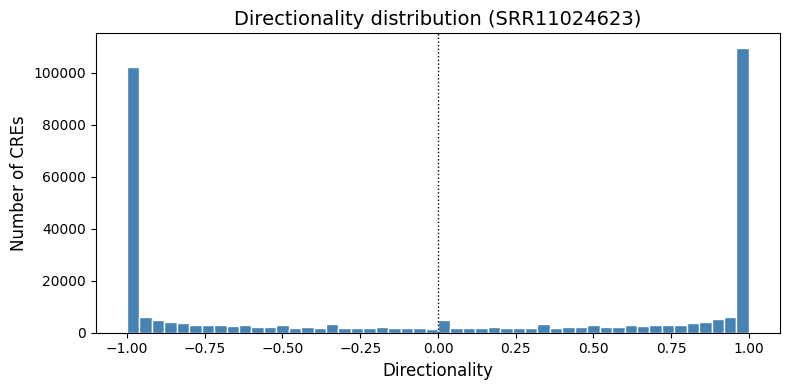

In [13]:
# Light QC: value range, null (zero-denominator) counts, one-sample histogram
dir_sample_cols = [c for c in proseq_directionality.columns if c not in ("cre_id", "size")]

# Per-sample null count and finite min/max
qc_rows = []
for srr in dir_sample_cols:
    col = pl.col(srr)
    qc_rows.append(
        {
            "srr": srr,
            "n_null": proseq_directionality.select(col.is_null().sum()).item(),
            "n_finite": proseq_directionality.select(col.is_not_null().sum()).item(),
            "min": proseq_directionality.select(col.min()).item(),
            "max": proseq_directionality.select(col.max()).item(),
        }
    )

dir_qc = pl.DataFrame(qc_rows)
display(dir_qc)

# Sanity: finite values should lie in [-1, 1]
out_of_range = (
    dir_qc.filter((pl.col("min") < -1.0 - 1e-9) | (pl.col("max") > 1.0 + 1e-9))
)
print(f"samples with values outside [-1, 1]: {out_of_range.height}")
if out_of_range.height > 0:
    display(out_of_range)

# Histogram for the first sample (finite values only)
example_srr = dir_sample_cols[0]
example_vals = (
    proseq_directionality
    .select(pl.col(example_srr).alias("directionality"))
    .drop_nulls()
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(example_vals["directionality"], bins=50, color="steelblue", edgecolor="white")
ax.set_xlabel("Directionality", fontsize=12)
ax.set_ylabel("Number of CREs", fontsize=12)
ax.set_title(f"Directionality distribution ({example_srr})", fontsize=14)
ax.axvline(0, color="black", linestyle=":", linewidth=1)
plt.tight_layout()
plt.show()


In [14]:
#check FCHS_354464 (related to HSPA1A)
FCHS_354464_plus_directionality = proseq_directionality.filter(pl.col("cre_id") == "FCHS_354464")
display(FCHS_354464_plus_directionality)

cre_id,size,SRR11024623,SRR11024624,SRR11024625,SRR11024626,SRR11024627,SRR11024628,SRR12267707,SRR12267708,SRR12267709,SRR12267710,SRR12267711,SRR12267712,SRR12267713,SRR12267714,SRR14352131,SRR14352132,SRR14352133,SRR14352134,SRR14352135,SRR14352136,SRR14352137,SRR14352138,SRR19077081,SRR19077082,SRR19077083,SRR19077084,SRR19077085,SRR19077086,SRR19077087,SRR19077088,SRR19077089,SRR19077090,SRR19077091,SRR19077092,SRR19077093,…,SRR23989382,SRR23989392,SRR23989393,SRR23989394,SRR23989395,SRR23989396,SRR23989397,SRR23989398,SRR23989399,SRR4454567,SRR4454568,SRR4454569,SRR4454570,SRR6904125,SRR6904126,SRR6904127,SRR6904128,SRR6904129,SRR6904130,SRR6904131,SRR6904132,SRR8669162,SRR8669163,SRR8669164,SRR8669165,SRR8669166,SRR8669167,SRR8669168,SRR8669169,SRR8669170,SRR8669171,SRR8669172,SRR8669173,SRR8669174,SRR8669175,SRR8669176,SRR8669177
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_354464""",600,-1.0,0.322451,0.109558,-0.2,0.533332,0.333332,0.958103,0.977901,0.900728,0.9701,0.953777,0.965173,0.951565,0.948966,0.392406,0.935702,0.566265,0.937985,0.900621,0.941003,0.744525,0.942371,0.269566,0.636364,null,-1.0,-0.649402,0.36842,null,-1.0,0.916667,0.962963,1.0,null,0.854369,…,0.987242,0.996719,0.990044,0.992989,0.994533,0.992101,1.0,0.996523,0.993929,0.980944,0.986072,0.974118,0.985666,1.0,-1.0,1.0,0.6,0.800866,0.809046,0.769437,0.68693,0.968447,0.972201,0.985007,0.987612,0.987525,0.968279,0.970487,0.987071,0.986291,0.983146,0.96248,0.944506,0.956518,0.962496,0.939559,0.940215


cre_id,srr,directionality,condition
str,str,f64,enum
"""FCHS_354464""","""SRR6904126""",-1.0,"""Control"""
"""FCHS_354464""","""SRR6904127""",1.0,"""Control"""
"""FCHS_354464""","""SRR8669162""",0.968447,"""Control"""
"""FCHS_354464""","""SRR21140721""",0.888889,"""Control"""
"""FCHS_354464""","""SRR8669172""",0.96248,"""Control"""
…,…,…,…
"""FCHS_354464""","""SRR8669166""",0.987525,"""Heat-stress"""
"""FCHS_354464""","""SRR23989378""",0.995199,"""Heat-stress"""
"""FCHS_354464""","""SRR21140726""",0.806451,"""Heat-stress"""


             count      mean       std       min       25%       50%  \
condition                                                              
Control       43.0  0.632116  0.649829 -1.000000  0.705596  0.962480   
Heat-stress   61.0  0.814293  0.289976 -0.649402  0.800866  0.941003   

                  75%  max  
condition                   
Control      0.990838  1.0  
Heat-stress  0.984128  1.0  


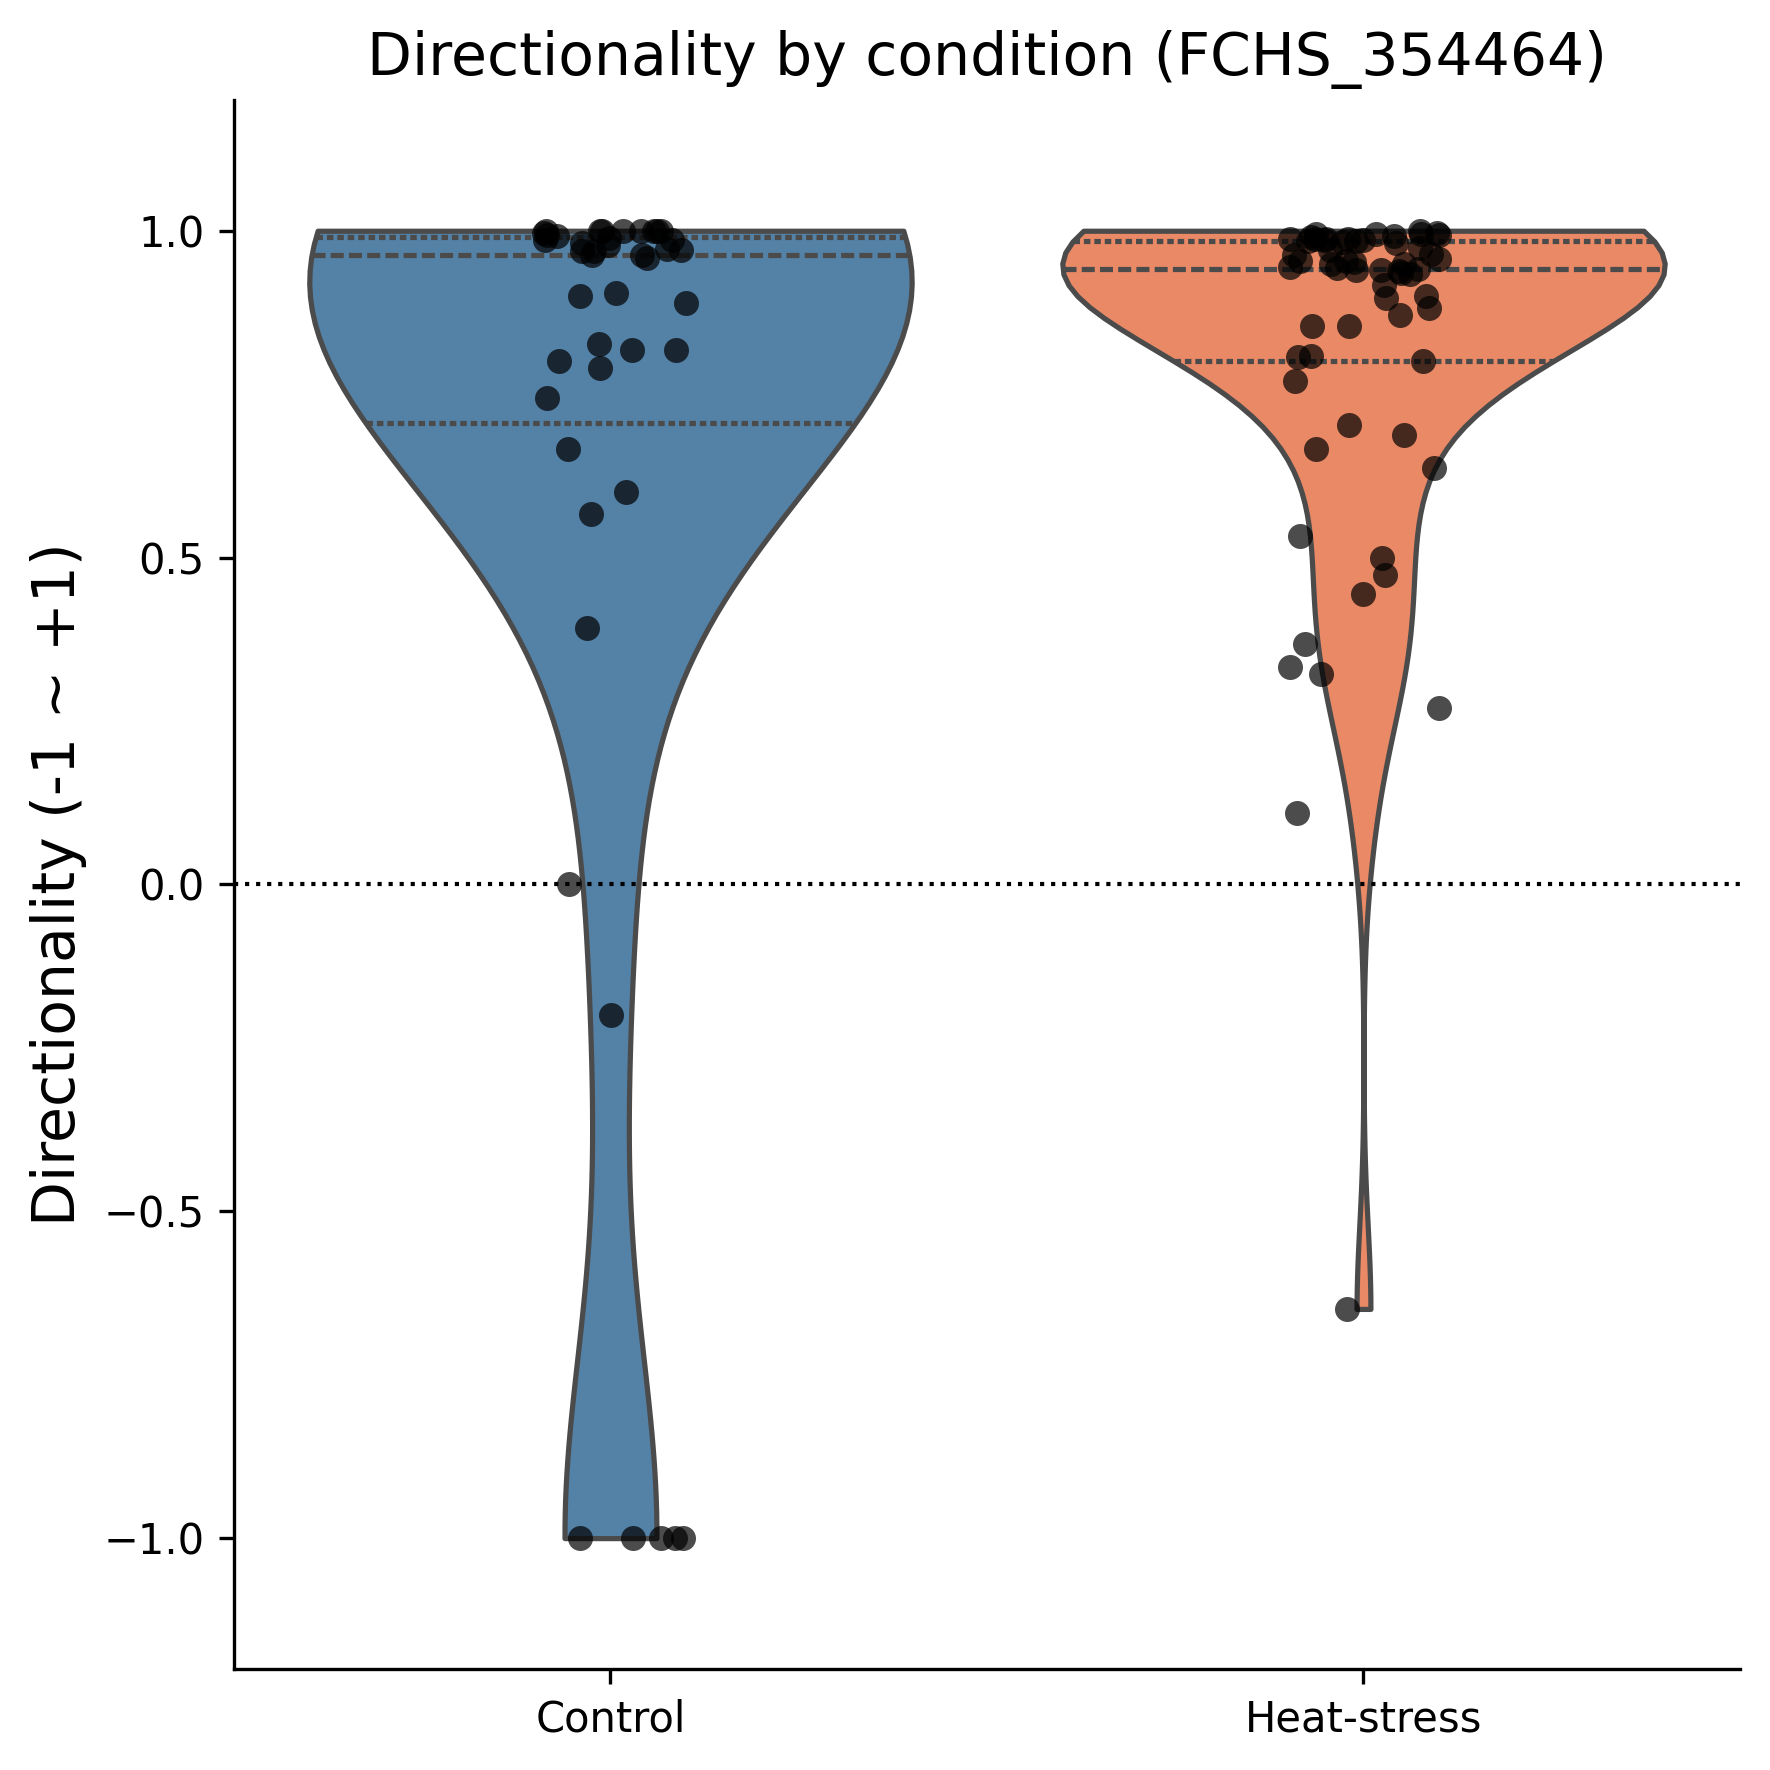

In [15]:
# Violin plot: directionality (y: -1..+1) vs condition (x: Heat-stress / Control)
# Example CRE = FCHS_354464 (HSPA1A-related). Nulls (F+R==0) are dropped.
EXAMPLE_CRE = "FCHS_354464"

dir_cols = [c for c in proseq_directionality.columns if c not in ("cre_id", "size")]

# SRRs present in the directionality matrix, split by metadata condition
heat_srrs = (
    metadata_proseq
    .select("sample_heat_id")
    .unique()
    .to_series()
    .to_list()
)
control_srrs = (
    metadata_proseq
    .select("sample_control_id")
    .unique()
    .to_series()
    .to_list()
)
heat_srrs = [s for s in heat_srrs if s in dir_cols]
control_srrs = [s for s in control_srrs if s in dir_cols]

condition_map = {s: "Heat-stress" for s in heat_srrs} | {s: "Control" for s in control_srrs}
plot_srrs = list(condition_map.keys())

# Wide -> long for one CRE
dir_long = (
    proseq_directionality
    .filter(pl.col("cre_id") == EXAMPLE_CRE)
    .select(["cre_id", *plot_srrs])
    .unpivot(index="cre_id", on=plot_srrs, variable_name="srr", value_name="directionality")
    .with_columns(
        pl.col("srr").replace_strict(condition_map).alias("condition")
    )
    .drop_nulls("directionality")
    .with_columns(
        pl.col("condition").cast(pl.Enum(["Control", "Heat-stress"]))
    )
    .sort("condition")
)

dir_viz = dir_long.to_pandas()
display(dir_long)
print(dir_viz.groupby("condition", observed=True)["directionality"].describe())

fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
sns.violinplot(
    data=dir_viz,
    x="condition",
    y="directionality",
    hue="condition",
    order=["Control", "Heat-stress"],
    palette={"Control": "steelblue", "Heat-stress": "coral"},
    inner="quartile",
    cut=0,
    legend=False,
    ax=ax,
)
sns.stripplot(
    data=dir_viz,
    x="condition",
    y="directionality",
    order=["Control", "Heat-stress"],
    color="black",
    size=6,
    alpha=0.7,
    ax=ax,
)
ax.set_ylim(-1.2, 1.2)
ax.axhline(0, color="black", linestyle=":", linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Directionality (-1 ~ +1)", fontsize=14)
ax.set_title(f"Directionality by condition ({EXAMPLE_CRE})", fontsize=14)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

cre_id,srr,directionality
enum,str,f64
"""FCHS_110516""","""SRR8669169""",-0.770437
"""FCHS_110516""","""SRR21140715""",-0.71246
"""FCHS_110516""","""SRR11024625""",0.621676
"""FCHS_110516""","""SRR21140725""",-0.740984
"""FCHS_110516""","""SRR6904132""",-0.280795
…,…,…
"""FCHS_354464""","""SRR12267714""",0.948966
"""FCHS_354464""","""SRR21140716""",0.953488
"""FCHS_354464""","""SRR8669170""",0.986291


             count      mean       std       min       25%       50%  \
cre_id                                                                 
FCHS_110516   61.0 -0.248773  0.491748 -0.862348 -0.702857 -0.398274   
FCHS_354464   61.0  0.814293  0.289976 -0.649402  0.800866  0.941003   

                  75%      max  
cre_id                          
FCHS_110516  0.339407  0.67183  
FCHS_354464  0.984128  1.00000  


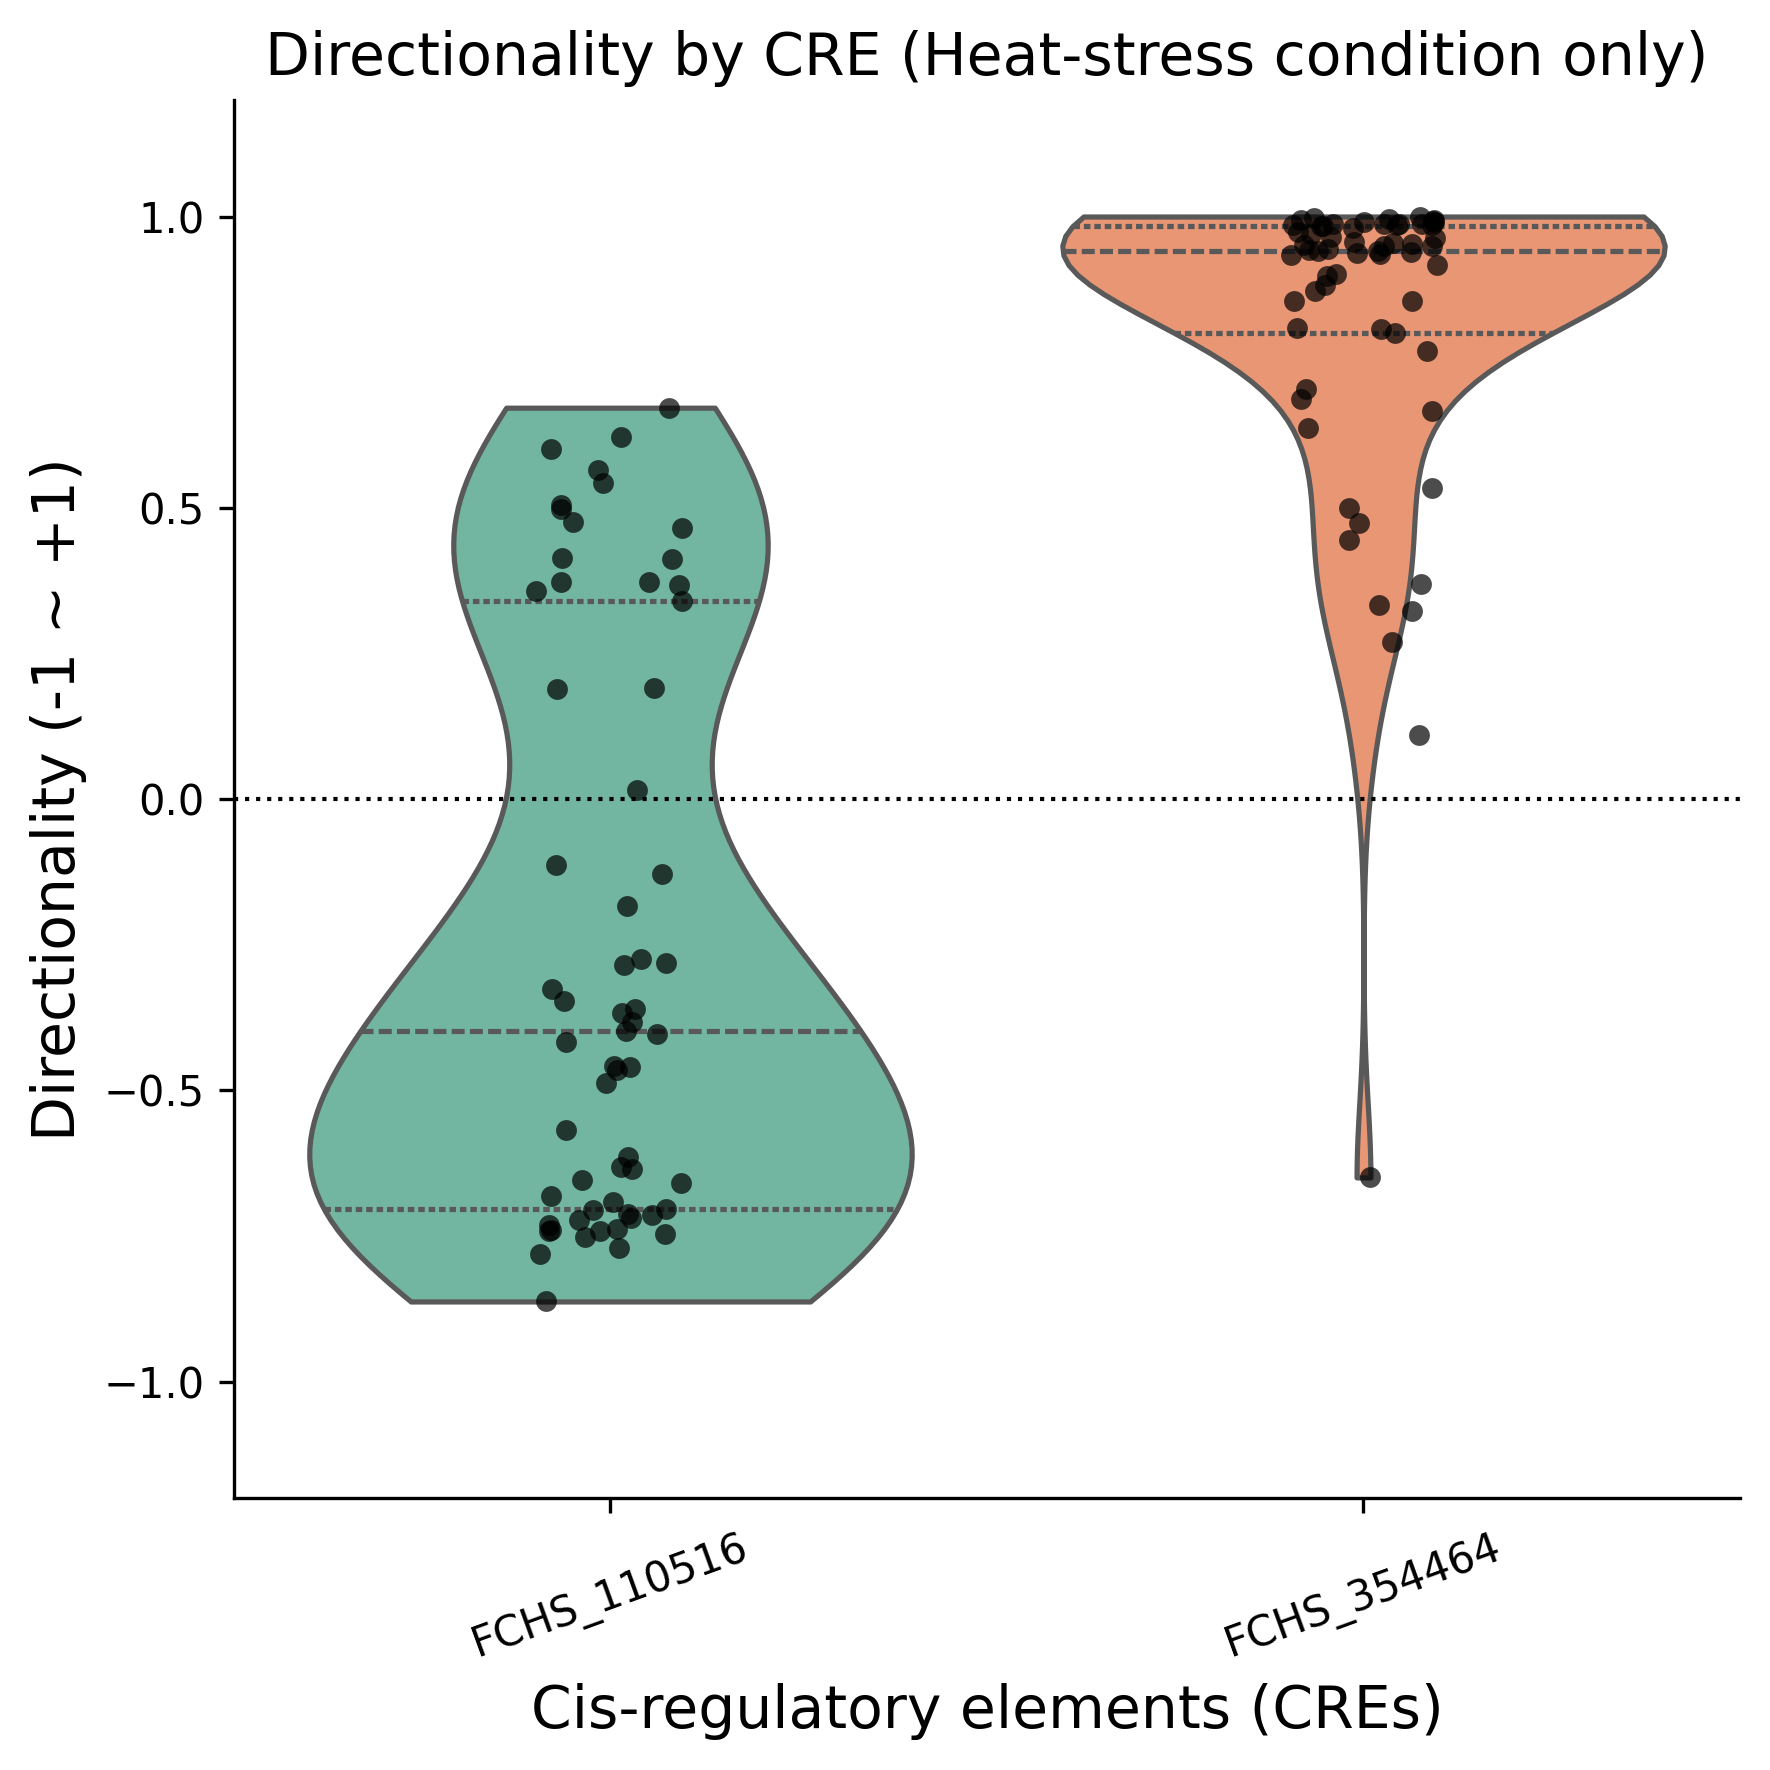

In [16]:
# Violin plot (Heat-stress only): directionality vs selected CREs
# Edit EXAMPLE_CRES (3~4 ids) to choose which cis-elements to compare.

EXAMPLE_CRES = [
    "FCHS_110516",  # HSPH1-related, maybe bidirectional
    "FCHS_354464"  # HSPA1A-related, plus-biased
]

dir_cols = [c for c in proseq_directionality.columns if c not in ("cre_id", "size")]

# Heat-stress SRRs only (present in the directionality matrix)
heat_srrs = (
    metadata_proseq
    .select("sample_heat_id")
    .unique()
    .to_series()
    .to_list()
)
heat_srrs = [s for s in heat_srrs if s in dir_cols]
if not heat_srrs:
    raise ValueError("No Heat-stress SRRs found in proseq_directionality")

present = set(
    proseq_directionality
    .filter(pl.col("cre_id").is_in(EXAMPLE_CRES))
    .get_column("cre_id")
    .unique()
    .to_list()
)
missing = [c for c in EXAMPLE_CRES if c not in present]
if missing:
    raise ValueError(f"CRE id(s) not found in proseq_directionality: {missing}")

# Wide -> long: selected CREs x Heat-stress SRRs
dir_long_hs = (
    proseq_directionality
    .filter(pl.col("cre_id").is_in(EXAMPLE_CRES))
    .select(["cre_id", *heat_srrs])
    .unpivot(index="cre_id", on=heat_srrs, variable_name="srr", value_name="directionality")
    .drop_nulls("directionality")
    .with_columns(
        pl.col("cre_id").cast(pl.Enum(EXAMPLE_CRES))
    )
    .sort("cre_id")
)

dir_viz_hs = dir_long_hs.sort("cre_id").to_pandas()
display(dir_long_hs)
print(dir_viz_hs.groupby("cre_id", observed=True)["directionality"].describe())

fig, ax = plt.subplots(figsize=(max(6, 1.8 * len(EXAMPLE_CRES)), 6), dpi=300)
sns.violinplot(
    data=dir_viz_hs,
    x="cre_id",
    y="directionality",
    hue="cre_id",
    order=EXAMPLE_CRES,
    palette="Set2",
    inner="quartile",
    cut=0,
    legend=False,
    ax=ax,
)
sns.stripplot(
    data=dir_viz_hs,
    x="cre_id",
    y="directionality",
    order=EXAMPLE_CRES,
    color="black",
    size=5,
    alpha=0.7,
    ax=ax,
)
ax.set_ylim(-1.2, 1.2)
ax.axhline(0, color="black", linestyle=":", linewidth=1)
ax.set_xlabel(f"Cis-regulatory elements (CREs)", fontsize=14)
ax.set_ylabel("Directionality (-1 ~ +1)", fontsize=14)
ax.set_title("Directionality by CRE (Heat-stress condition only)", fontsize=14)
ax.tick_params(axis="x", rotation=20)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
